# 02 · LDA dimensionality reduction

Linear Discriminant Analysis searches for directions that maximize between-class separation relative to within-class variation. With three classes, at most two discriminant axes are available, so this dataset has a natural 13 → 2 supervised reduction.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
ROOT

PosixPath('/mnt/data/wine_lda_portfolio')

In [2]:
from src.data import load_raw, clean_data
from src.modeling import fit_full_lda
clean=clean_data(load_raw())
scaler, lda, Z, coef, means, scalings = fit_full_lda(clean)
lda.explained_variance_ratio_

array([0.68747889, 0.31252111])

## Reduced coordinates

In [3]:
Z.head()

,LD1,LD2,cultivar
0,-4.700244,1.979138,1
1,-4.301958,1.170413,1
2,-3.420720,1.429101,1
3,-4.205754,4.002871,1
4,-1.509982,0.451224,1


## Discriminant scalings

The scalings describe the linear combination of standardized chemical measurements used to form LD1 and LD2.

In [4]:
scalings.round(4)

,LD1,LD2
alcohol,-0.3266,0.7058
malic_acid,0.1841,0.3402
ash,-0.1010,0.6418
alcalinity_of_ash,0.5155,-0.4875
magnesium,-0.0308,-0.0066
total_phenols,0.3857,-0.0201
flavanoids,-1.6546,-0.4901
nonflavanoid_phenols,-0.1856,-0.2024
proanthocyanins,0.0765,-0.1753
color_intensity,0.8208,0.5854


In [5]:
strength=(scalings.pow(2).sum(axis=1).pow(0.5)).sort_values(ascending=False)
strength.to_frame('discriminant_strength').head(10)

,discriminant_strength
flavanoids,1.725673
proline,1.231594
color_intensity,1.008179
od280_od315,0.820345
alcohol,0.777648
alcalinity_of_ash,0.709488
ash,0.649654
hue,0.392562
malic_acid,0.386811
total_phenols,0.386244


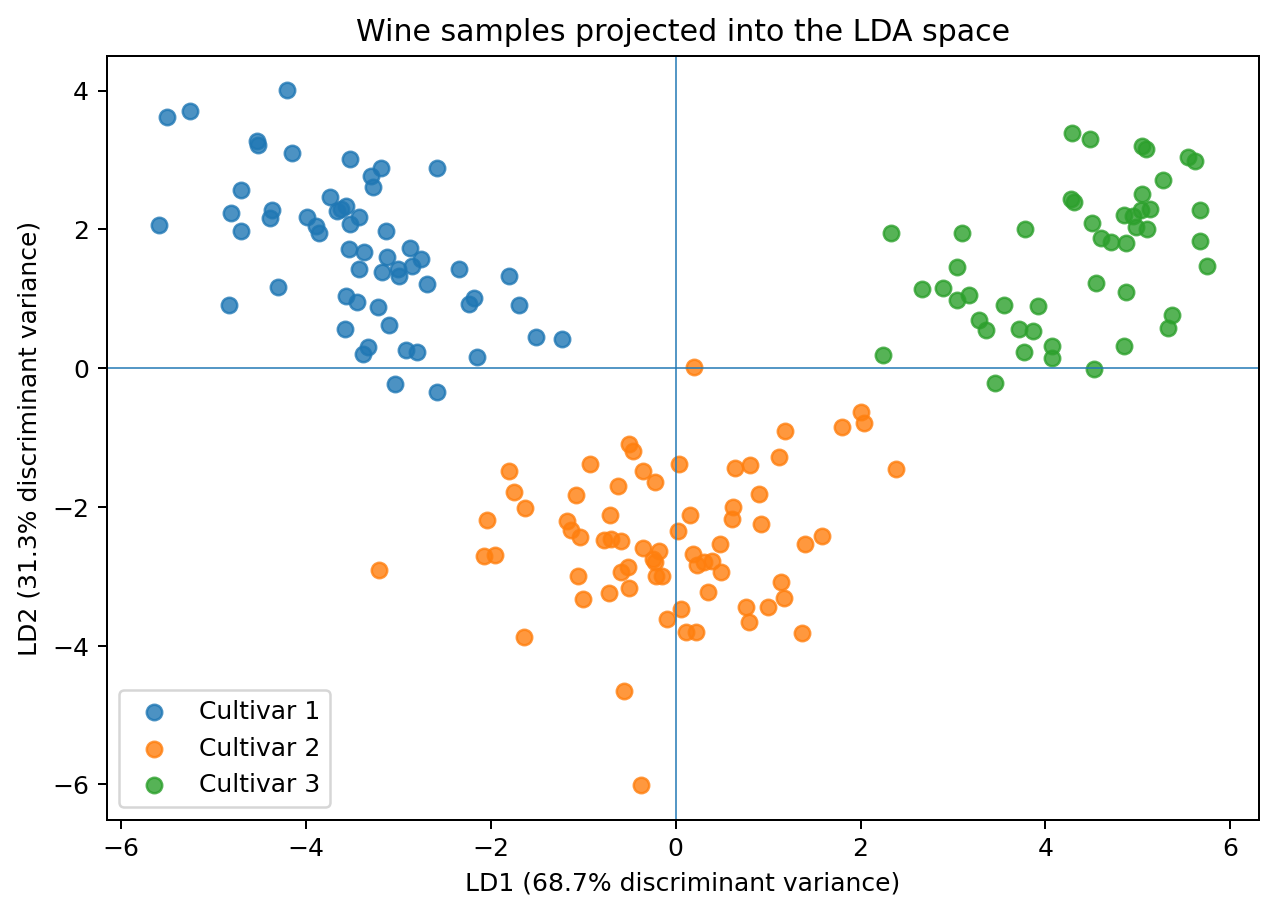

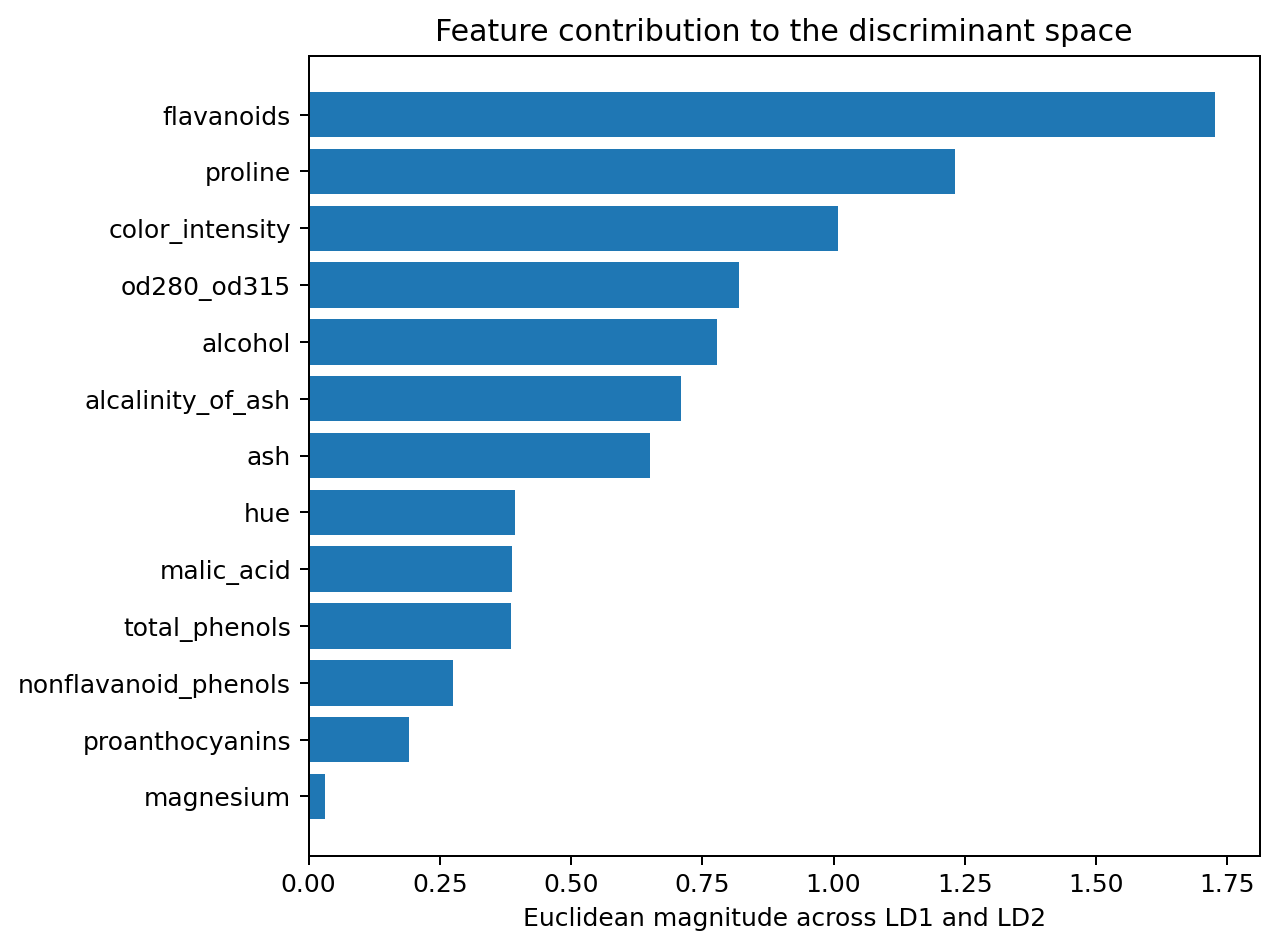

In [6]:
from IPython.display import Image, display
display(Image(filename=str(ROOT/'outputs/figures/lda_projection.png')))
display(Image(filename=str(ROOT/'outputs/figures/feature_discriminant_strength.png')))

## Interpretation

The 2D projection is not an unsupervised compression like PCA: class labels participate in choosing the axes. The result is therefore specifically optimized to distinguish the cultivars.